<small>
Copyright © 2025–2026 École Polytechnique Fédérale de Lausanne (EPFL). All rights reserved.
</small>

---

# Exercise 9 | Nonlinear Model Predictive Control

Consider a slot car racing track described by the 2D curve $(x(\lambda),y(\lambda))\in\mathbb{R}^2$ parametrized by the progress variable $\lambda\in\mathbb{R}$. The position of the car is entirely determined by $\lambda$ and its velocity by $v=\dot{\lambda}$, allowing us to model it using the state $x=(\lambda, v)$.

The curvature of the track is given by a function $\kappa(\lambda)$ and the car is known to flip out from the track if the speed $v$ exceeds a maximum speed $\bar{v}(\lambda)$, which decreases as the curvature $\kappa(\lambda)$ increases.

The car actuation can be modeled using an acceleration input $a$ and a braking input $b$, making up the control vector $u=(a,b)$.

The dynamics of the car can then be written as
$$
\begin{align*}
    \dot{\lambda} & = v, \\
    \dot{v} & = 5a - 6.6 b v - 0.01 v^3,
\end{align*}
$$
where the cubic term corresponds to a viscous friction coming from the track surface and air resistance.
We will denote this continuous-time dynamics as $\dot{x} = f(x,u)$.

Your goal in this notebook will be to implement a Nonlinear Model Predictive Control (NMPC) scheme to control the car around the track while avoiding flipping out.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scaly as sc
from scipy.integrate import solve_ivp
from ipywidgets import interact

np.random.seed(0)

## Problem 1: Discretization of the dynamics

Recall that for a given initial time $t_0$ and an integration step $h$, the state at time $t_0+h$ is given by $$ x(t_0+h) = x(t_0) + \int_{0}^{h} f(x(t_0+s),u(t_0+s)) ds. $$

There are several methods for approximating this integration for a constant input (i.e., when $u(t_0+s) = u(t_0)$ for all $s\in[0,h]$), like Euler and Runge-Kutta methods.

### Task 1
Implement Euler and 4th order Runge-Kutta (RK4) discretization methods to define the discrete-time dynamics $ x_{k+1} = f_d(x_k,u_k) $.
Test your integrators with the initial conditions $x(t_0) = (0, 0.5), u(t_0) = (0.0, 0.2)$.

In [2]:
def f(x, u):
    return np.array([x[1], 5 * u[0] - 6.6 * u[1] * x[1] - 0.01 * x[1] ** 3])


def euler(f, x, u, h):
    return x + h * f(x, u)


def rk4(f, x, u, h):
    k1 = h * f(x, u)
    k2 = h * f(x + k1 / 2, u)
    k3 = h * f(x + k2 / 2, u)
    k4 = h * f(x + k3, u)
    return x + (k1 + 2 * k2 + 2 * k3 + k4) / 6

In [3]:
x0 = np.array([0.0, 0.5])
u0 = np.array([0.0, 0.2])
h = 0.01
print("The next state computed from Euler integrator is: ", euler(f, x0, u0, h))
print("The next state computed from RK4 integrator is: ", rk4(f, x0, u0, h))

The next state computed from Euler integrator is:  [0.005     0.4933875]
The next state computed from RK4 integrator is:  [0.00496708 0.49343119]


### Task 2
For $x(0)=(0,0.5)$ and $u(t)=(0,0.2)$, simulate the system for 10 seconds with both integrators for $h=0.1\,\mathrm{s}$ and $h=0.5\,\mathrm{s}$.
Plot and compare the resulting trajectories with the ones given by the `ode45` integrator defined for you below.

In [4]:
def ode45(f, x, u, h):
    return solve_ivp(lambda t, x: f(x, u), [0, h], x, method="RK45").y[:, -1]

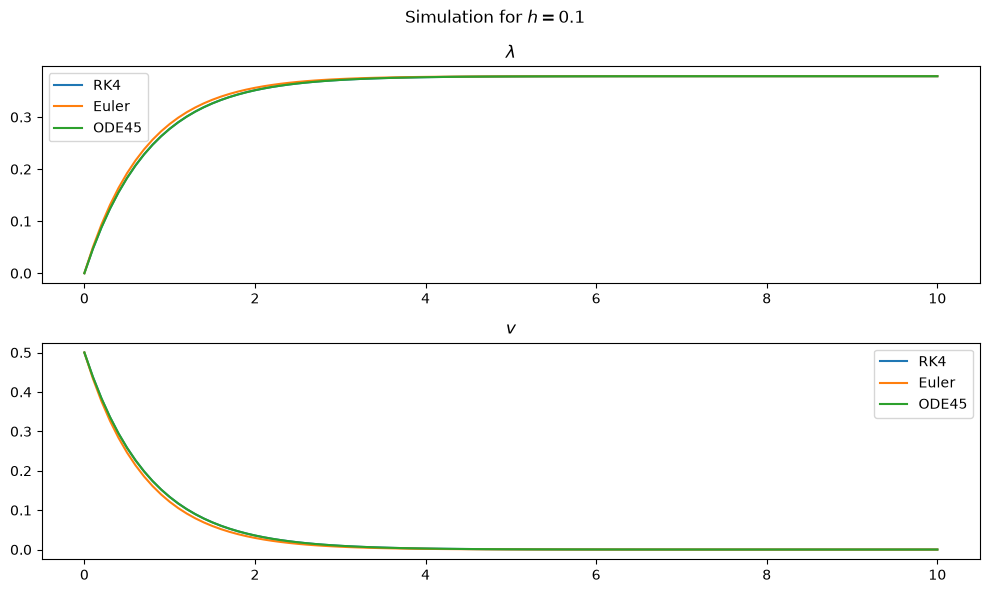

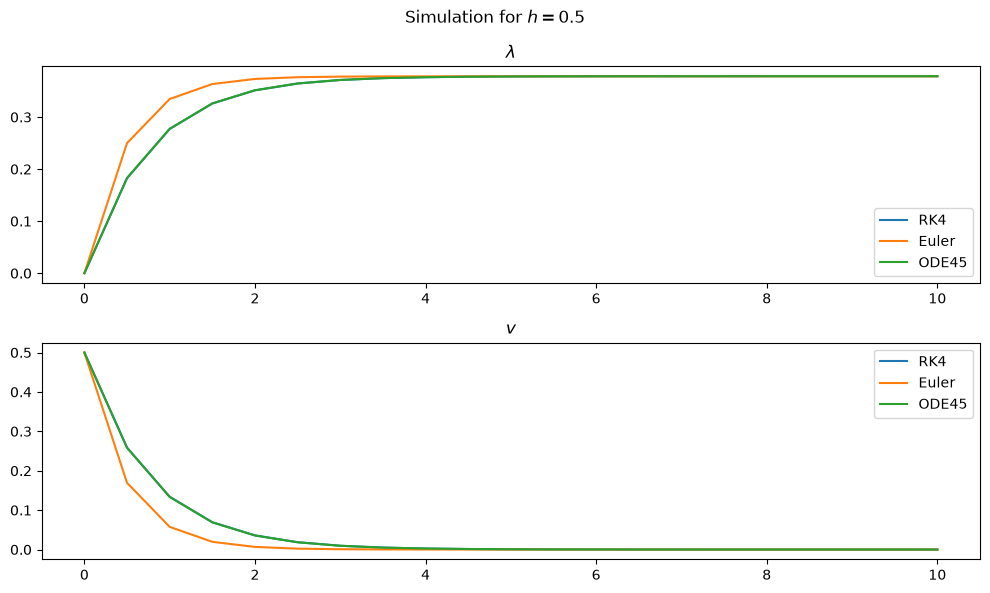

In [5]:
x0 = np.array([0.0, 0.5])
u0 = np.array([0.0, 0.2])
Tsim = 10
for h in [0.1, 0.5]:
    Nsim = int(Tsim / h)
    x_euler = np.zeros((Nsim + 1, 2))
    x_euler[0] = x0
    x_rk4 = np.zeros((Nsim + 1, 2))
    x_rk4[0] = x0
    x_ode45 = np.zeros((Nsim + 1, 2))
    x_ode45[0] = x0
    t = np.linspace(0, Tsim, Nsim + 1)
    for i in range(Nsim):
        x_rk4[i + 1] = rk4(f, x_rk4[i], u0, h)
        x_euler[i + 1] = euler(f, x_euler[i], u0, h)
        x_ode45[i + 1] = ode45(f, x_ode45[i], u0, h)

    plt.figure(figsize=(10, 6))
    plt.suptitle(rf"Simulation for $h = {h}$")

    plt.subplot(2, 1, 1)
    plt.title(r"$\lambda$")
    plt.plot(t, x_rk4[:, 0], label="RK4")
    plt.plot(t, x_euler[:, 0], label="Euler")
    plt.plot(t, x_ode45[:, 0], label="ODE45")
    plt.legend()

    plt.subplot(2, 1, 2)
    plt.title(r"$v$")
    plt.plot(t, x_rk4[:, 1], label="RK4")
    plt.plot(t, x_euler[:, 1], label="Euler")
    plt.plot(t, x_ode45[:, 1], label="ODE45")
    plt.legend()

    plt.tight_layout()

plt.show()

## Problem 2: Nonlinear Model Predictive Control

Now that you know more about how to discretize the dynamics, you are ready to implement the NMPC controller.

We will use [scaly](https://github.com/PREDICT-EPFL/scaly), a library that allows you to define symbolic expressions and compute their derivatives using algorithmic differentiation. We recommend starting with its [getting started guide](https://predict-epfl.github.io/scaly/guide/getting_started/), which introduces symbolic expressions (`sc.Expr`), functions (`sc.Function`), derivatives and optimization problems on a small control example.

To formulate the optimization problem in a simple way, we will use the `@sc.problem` decorator, which builds a symbolic optimization problem from its decision variables and parameters, and `sc.solver`, which solves it numerically with IPOPT.
We recommend reading the [solvers guide](https://predict-epfl.github.io/scaly/guide/solvers/) to have a good overview of their capabilities, in particular:
- [grouped variables and parameters](https://predict-epfl.github.io/scaly/guide/solvers/#grouped-variables-and-parameters) for `sc.group`,
- [bounded expressions](https://predict-epfl.github.io/scaly/guide/solvers/#bounded-expressions) for the inequality constraints written with `sc.bounded`,
- [numerical calls and return values](https://predict-epfl.github.io/scaly/guide/solvers/#numerical-calls-and-return-values) for what the solver returns and how to check its status.

For the dynamics constraints, [`sc.vmap`](https://predict-epfl.github.io/scaly/guide/functions/#regular-repetition-vmap) applies a function to every stage of the horizon at once.

You will find below some utility functions for generating a track and for plotting the NMPC predictions or the closed-loop trajectory.

In [6]:
# a function of one array of any shape, called with an sc.Expr or a np.ndarray
TrackFunction = sc.Function[tuple[sc.Expr], tuple[np.ndarray], sc.Expr, np.ndarray]


def generate_track(track_type: str) -> dict[str, TrackFunction]:
    if track_type == "complex":
        # drawn here rather than in pos, whose body runs again for each new shape of s
        wx = np.random.randn(3)
        wy = np.random.randn(3)
    elif track_type != "simple":
        raise ValueError(f"Unknown track type: {track_type}")

    @sc.function(sc.arg("s"))
    def pos(s: sc.Expr) -> sc.Expr:
        if track_type == "simple":
            return sc.stack([np.pi * (2 * np.pi * s).sin(), (4 * np.pi * s).sin()])
        return sc.stack(
            [
                wx[0] * (2 * np.pi * s).sin()
                + wx[1] * (4 * np.pi * s).sin()
                + wx[2] * (6 * np.pi * s).sin(),
                wy[0] * (2 * np.pi * s).sin()
                + wy[1] * (4 * np.pi * s).sin()
                + wy[2] * (6 * np.pi * s).sin(),
            ]
        )

    # the shape of s is left open so that these functions apply elementwise to arrays of any shape
    @sc.function(sc.arg("s"))
    def curvature(s: sc.Expr) -> sc.Expr:
        # derivatives of the elementwise function pos along s
        ones = sc.const(np.ones(s.shape))
        dpos = sc.jvp(pos(s), s, ones)
        ddpos = sc.jvp(dpos, s, ones)
        return ((dpos[0] * ddpos[1] - dpos[1] * ddpos[0]) / (dpos[0] ** 2 + dpos[1] ** 2) ** 1.5).abs()

    svals = np.linspace(0, 1, 100000)
    spd = 1 / (1 + curvature(svals))
    mx, mn = np.max(spd), np.min(spd)
    a = 0.9 / (mx - mn)
    b = 0.1 - a * mn

    # compute arc length parametrization

    # lam is the arc length. We need a function lambda -> s
    # => 1. evaluate lam at different s values
    # => 2. Since the sequences are monotonic, the inverse mapping is trivial
    # => 3. Since s - lam is periodic, fit it with a Fourier series (least squares on every 5th point)
    posvals = pos(svals)
    diffs = np.linalg.norm(np.diff(posvals, axis=1), axis=0)
    lams = np.insert(np.cumsum(diffs), 0, 0.0)
    lams = lams / lams[-1]  # normalized distance
    K = 30  # number of harmonics
    k = np.arange(1, K + 1)
    basis = np.column_stack([np.ones(len(lams)), np.cos(2 * np.pi * np.outer(lams, k)), np.sin(2 * np.pi * np.outer(lams, k))])
    c = np.linalg.lstsq(basis[::5], (svals - lams)[::5])[0]

    @sc.function(sc.arg("lam"))
    def param(lam: sc.Expr) -> sc.Expr:
        return lam + c[0] + sum(c[i] * (2 * np.pi * i * lam).cos() + c[K + i] * (2 * np.pi * i * lam).sin() for i in k)

    # convert all previous functions into functions of lam
    @sc.function(sc.arg("lam"))
    def maxspeed(lam: sc.Expr) -> sc.Expr:
        return a / (1 + curvature(param(lam))) / mx + b

    @sc.function(sc.arg("lam"))
    def pos_lam(lam: sc.Expr) -> sc.Expr:
        return pos(param(lam))

    return {
        # used for mpc
        "maxspeed": maxspeed,
        # used for plotting
        "pos": pos_lam,
    }


def plot_curves(
    track: dict[str, TrackFunction],
    lam: np.ndarray,
    speed: np.ndarray,
    accel: np.ndarray,
    brake: np.ndarray,
    epsilon_speed: np.ndarray,
    title: str,
):
    t = h * np.arange(len(lam))
    plt.figure(figsize=(10, 6))
    plt.title(title)
    plt.plot(t, track["maxspeed"](lam), "k--", linewidth=2, label="max speed")
    plt.plot(t, lam, linewidth=2, label="lam")
    plt.plot(t, speed, linewidth=2, label="speed")
    plt.step(t, np.append(accel, accel[-1]), linewidth=2, label="accel", where="post")
    plt.step(t, -np.append(brake, brake[-1]), linewidth=2, label="brake", where="post")
    plt.fill_between(t, speed-epsilon_speed, speed, color="gray", alpha=0.5, label="speed margin")
    plt.legend()
    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()


def plot_track( track: dict[str, TrackFunction], lam: np.ndarray, lam_predictions: np.ndarray):
    # Generate track points for visualization
    lam_track = np.linspace(0, 1, 500)
    track_pos = track["pos"](lam_track)
    track_maxspeed = track["maxspeed"](lam_track)

    def plot_at_timestep(k):
        fig, ax = plt.subplots(figsize=(10, 10))

        # Plot track with color indicating max speed
        scatter = ax.scatter(
            track_pos[0, :],
            track_pos[1, :],
            c=track_maxspeed,
            cmap='RdYlGn',
            s=20,
            alpha=0.6,
            label='Track'
        )

        # Add colorbar
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label('Max Speed', rotation=270, labelpad=20)

        # Plot current car position
        car_pos = track["pos"](lam[k])
        ax.plot(car_pos[0], car_pos[1], 'bo', markersize=15, label='Car Position', zorder=5)

        # Plot NMPC predictions (white points)
        if k < lam_predictions.shape[1]:
            pred_positions = track["pos"](lam_predictions[:, k])
            ax.plot(pred_positions[0, :], pred_positions[1, :], 'wo',
                   markersize=6, markeredgecolor='black', markeredgewidth=1,
                   label='NMPC Predictions', zorder=4)
            # Connect predictions with a line
            ax.plot(pred_positions[0, :], pred_positions[1, :], 'w--',
                   linewidth=1.5, alpha=0.7, zorder=3)

        ax.set_xlabel('X Position')
        ax.set_ylabel('Y Position')
        ax.set_title(f'Track Visualization - Time Step {k} (t = {k*h:.3f}s)')
        ax.legend(loc='upper right')
        ax.axis('equal')
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    # Create interactive slider
    interact(plot_at_timestep, k=(0, len(lam)-1, 1))

In [7]:
N = 10
h = 0.025
track = generate_track("simple")
# track = generate_track("complex")

### Task 1

The NMPC we will implement is the following

$$
\begin{align*}
\min_{x_k, u_k, \epsilon_k} \quad & \sum_{k=0}^{N-1} \left(-10 v_k + 0.1 a_k^2 + 1000 b_k^2 + 10000 (\epsilon_k^2 + \epsilon_k) \right) - 10v_N+10000(\epsilon_N^2 + \epsilon_N) \\
\text{s.t.} \quad & x_0 = x_{\mathrm{init}},\\
& x_{k+1} = f_d(x_k, u_k), \quad k=0,\ldots,N-1, \\
& v_k \leq \bar{v}(\lambda_k) + \epsilon_k, \quad k=0,\ldots,N,\\
& \epsilon_k \geq 0, \quad k=0,\ldots,N,\\
& 0 \leq a_k,b_k \leq 1, \quad k=0,\ldots,N-1.
\end{align*}
$$

Note the following:
- the cost function has a negative coefficient on the velocity to maximize it, and some penalties on the acceleration and braking inputs to avoid aggressive maneuvers.
- the velocity upper bound is given by the function $\bar{v}$ that depends on the track. In the code you can access it using `track["maxspeed"](lam)` where `lam` is a scaly symbolic expression or a numpy array. 
- this constraint is softened using a slack variable $\epsilon_k$ to ensure feasibility of the optimization problem at all times. A high penalty is added to the cost function to discourage the use of this slack variable.

Your task is to complete the `create_nmpc` function below by implementing the constraints of our NMPC problem.
A lot has been implemented for you, but we still encourage you to read the whole function and try to understand it.

Quickly test your implementation by looking at the open-loop prediction for a single initial state $x_{\mathrm{init}}=(0,0)$.

In [8]:
# the continuous dynamics as an sc.Function
@sc.function(sc.arg("x", 2), sc.arg("u", 2))
def f_scaly(x: sc.Expr, u: sc.Expr) -> sc.Expr:
    return sc.stack([x[1], 5 * u[0] - 6.6 * u[1] * x[1] - 0.01 * x[1] ** 3])


# h is read once, when f_d_scaly is defined: rerun this cell after changing h
@sc.function(sc.arg("x", 2), sc.arg("u", 2))
def f_d_scaly(x: sc.Expr, u: sc.Expr) -> sc.Expr:
    return rk4(f_scaly, x, u, h)


def create_nmpc():
    @sc.problem(
        # decision variables
        vars=sc.group(
            sc.arg("X", (N + 1, 2)),
            sc.arg("U", (N, 2)),
            sc.arg("epsilon_speed", N + 1),  # slack variable for speed constraint
        ),
        # optimization parameters
        params=sc.arg("x_init", 2),
    )
    def nmpc_problem(variables: tuple[sc.Expr, sc.Expr, sc.Expr], x_init: sc.Expr) -> sc.ProblemSpec:
        X, U, epsilon_speed = variables
        lam = X[:, 0]
        speed = X[:, 1]
        accel = U[:, 0]
        brake = U[:, 1]

        # objective function
        cost = (
            # max velocity
            -10 * speed.sum()
            # minimize acceleration
            + 0.1 * sc.sumsqr(accel)
            # minimize braking
            + 1000 * sc.sumsqr(brake)
            # L1 and L2 penalties on slack variables
            + 10000 * (sc.sumsqr(epsilon_speed) + epsilon_speed.sum())
        )

        # equality constraints are expressions constrained to zero, and inequality
        # constraints are written as sc.bounded(expression, lo=..., hi=...)
        # initial conditions
        initial_conditions = X[0] - x_init

        # dynamics constraints, for all k at once: sc.vmap(f_d_scaly, N) applies f_d_scaly to
        # every row of its arguments and compiles to one loop instead of N copies
        dynamics = (X[1:] - sc.vmap(f_d_scaly, N)(X[:-1], U)).vec()

        # velocity constraints
        velocity_constraints = sc.bounded(speed - track["maxspeed"](lam) - epsilon_speed, hi=0.0)

        # input constraints
        input_constraints = sc.bounded(U.vec(), lo=0.0, hi=1.0)

        # slack variable constraints
        slack_constraints = sc.bounded(epsilon_speed, lo=0.0)  # positive slack variable

        return sc.ProblemSpec(
            minimize=cost,
            eq=(initial_conditions, dynamics),
            ineq=(velocity_constraints, input_constraints, slack_constraints),
        )

    # set solver
    options = {"sb": "yes", "print_level": 0, "tol": 1e-3}
    return sc.solver(nmpc_problem, "ipopt", options=options)

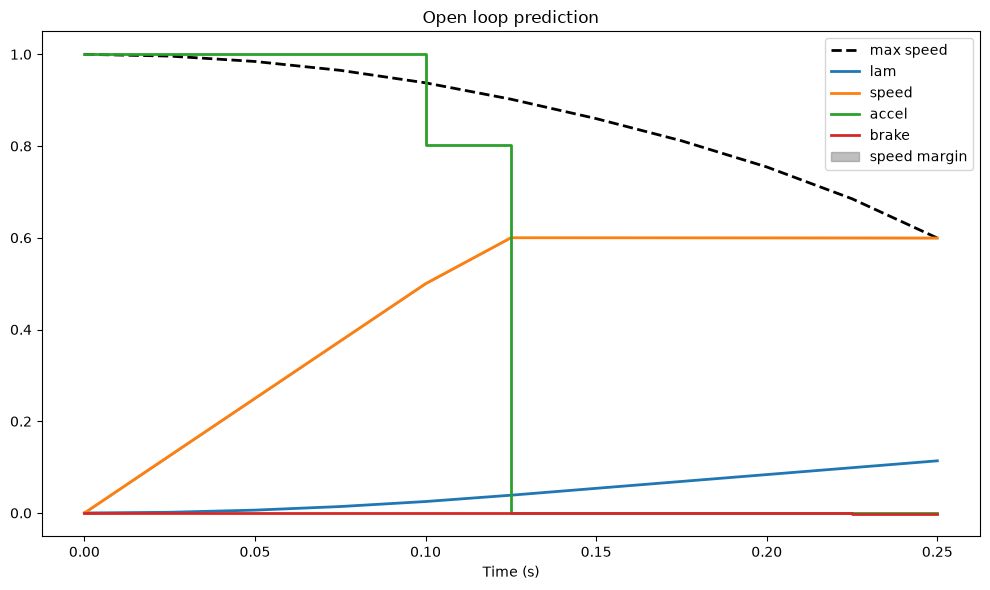

In [9]:
nmpc = create_nmpc()
# solve the problem for the initial state (the first call compiles the solver, so it takes a few seconds)
# the solver returns the optimal variables, with the structure declared in vars, followed by the multipliers
(X, U, eps), *_ = nmpc(np.array([0.0, 0.0]))
assert nmpc.stats().to_solver_status().ok

plot_curves(
    track,
    X[:, 0],
    X[:, 1],
    U[:, 0],
    U[:, 1],
    eps,
    "Open loop prediction",
)

### Task 2

Now, you will test your controller in a closed-loop simulation around the racing track. Complete the code below to specify the current state, call the solver and extract the optimal control to apply to the system.

In the plots below you will see the evolution of each state and control throughout the simulation, as well as the position open-loop predictions of the NMPC at each time step.

If you go back a few cells and generate a 'complex' track, you should see that the velocity constraint is sometimes violated. Try tuning the cost function weights to reduce this effect.

In [10]:
# closed loop simulation
states = [np.array([0.0, 0.0])]
controls = []
epsilon_speed = [0.0]
lam_predictions = []
i = 0
while states[-1][0] < 1:  # take one loop around the track
    i += 1

    # solve the MPC problem from the current state
    (X, U, eps), *_ = nmpc(states[-1])
    u_mpc = U[0]
    assert nmpc.stats().to_solver_status().ok

    # simulate next step and log values
    controls.append(u_mpc)
    states.append(f_d_scaly(states[-1], controls[-1]))
    epsilon_speed.append(eps[0])
    lam_predictions.append(X[:, 0])

states = np.column_stack(states)
controls = np.column_stack(controls)
epsilon_speed = np.array(epsilon_speed)
lam_predictions = np.column_stack(lam_predictions)

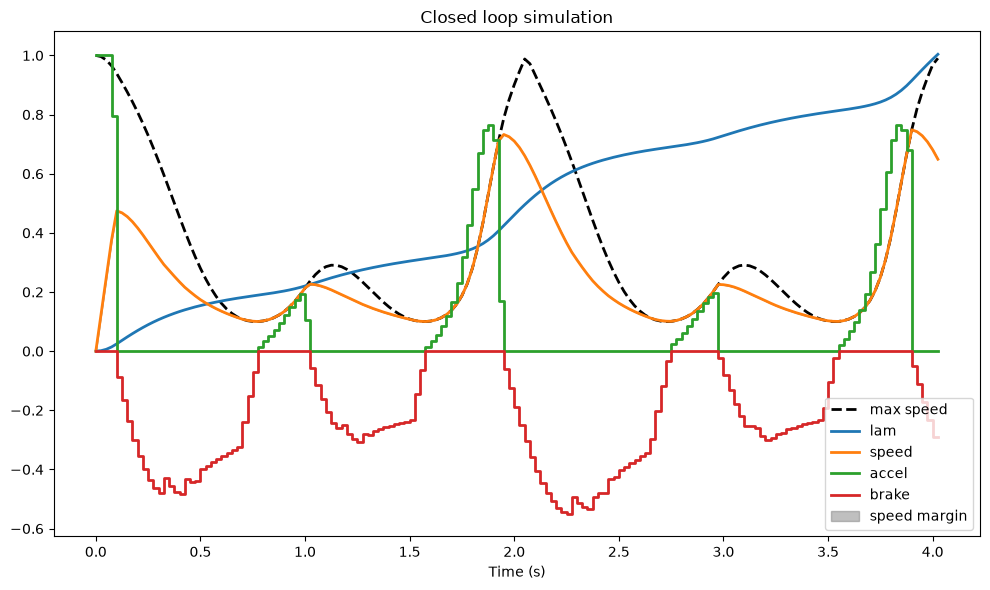

interactive(children=(IntSlider(value=80, description='k', max=161), Output()), _dom_classes=('widget-interact…

In [11]:
# plot closed loop results
plot_curves(
    track,
    states[0],
    states[1],
    controls[0],
    controls[1],
    epsilon_speed,
    "Closed loop simulation",
)
plot_track(track, states[0], lam_predictions)